# Chapter 12 – Example 12.3

## Mechanism Synthesis Publications Timeline (1990–2025)

**Objective:** Model and visualize the growth of publications in mechanism synthesis using Genetic Algorithms (GA) and neural networks. Calculate the Compound Annual Growth Rate (CAGR) and identify key periods of technological evolution.

### 1. Growth Model

In [ ]:
from numpy import *
import builtins

anios = arange(1990, 2026)

# Model components
base = 2 + 0.3 * (anios - 1990)
pico_ga = 8 * exp(-0.5 * ((anios - 2003) / 4) ** 2)    # GA boom ≈ 2000-2006
pico_nn = 15 * exp(-0.5 * ((anios - 2018) / 3) ** 2)   # deep learning boom
pico_hyb = 10 * exp(-0.5 * ((anios - 2021) / 3) ** 2)  # hybrid approaches

publicaciones = around(base + pico_ga + pico_nn + pico_hyb + 1).astype(int)

# Statistics
total = publicaciones.sum()
cagr = (publicaciones[-1] / publicaciones[0]) ** (1 / (len(anios) - 1)) - 1
idx_p = argmax(publicaciones)
p2015 = publicaciones[anios >= 2015].sum()

print("Publication Analysis 1990–2025")
print(f"{'='*40}")
print(f"Cumulative Total:        {total} publications")
print(f"CAGR (1990→2025):        {100*cagr:.1f}% annually")
print(f"Peak Year:               {anios[idx_p]} ({publicaciones[idx_p]} pub.)")
print(f"Publications 2015–2025:  {p2015} ({100*p2015/total:.1f}% of total)")
print()

print("Publications per decade:")
for inicio in [1990, 2000, 2010, 2020]:
    fin = builtins.min(inicio + 10, 2026)
    mask = (anios >= inicio) & (anios < fin)
    print(f"  {inicio}s: {publicaciones[mask].sum():>4} pub. "
          f"(mean {publicaciones[mask].mean():.1f}/year)")

Publication Analysis 1990–2025
Cumulative Total:        557 publications
CAGR (1990→2025):        5.4% annually
Peak Year:               2019 (34 pub.)
Publications 2015–2025:  298 (53.5% of total)

Publications per decade:
  1990s:   60 pub. (mean 6.0/year)
  2000s:  134 pub. (mean 13.4/year)
  2010s:  206 pub. (mean 20.6/year)
  2020s:  157 pub. (mean 26.2/year)


### 2. Stacked Area Chart Visualization

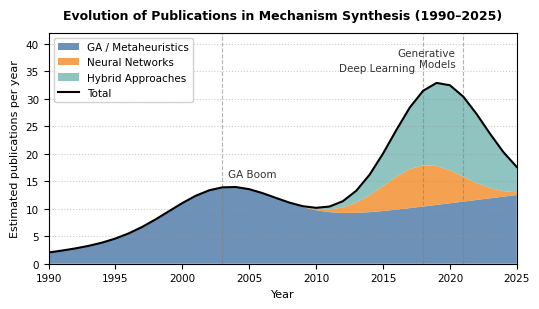

In [10]:
import matplotlib.pyplot as plt
import os
import glob
from numpy import arange, exp

# 1. Automated Filename System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex12_3_publications_timeline"
except Exception:
    notebook_name = "ex12_3_publications_timeline"

# 2. Springer Publication Style Settings
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# Ensure required variables are defined locally if the previous cell wasn't run
try:
    _ = anios, base, pico_ga, pico_nn, pico_hyb
except NameError:
    anios = arange(1990, 2026)
    base = 2 + 0.3 * (anios - 1990)
    pico_ga = 8 * exp(-0.5 * ((anios - 2003) / 4) ** 2)
    pico_nn = 15 * exp(-0.5 * ((anios - 2018) / 3) ** 2)
    pico_hyb = 10 * exp(-0.5 * ((anios - 2021) / 3) ** 2)

# Data calculations (realigned components based on base and peak values)
ga_only  = base + pico_ga
nn_only  = 0.5 * pico_nn
hybrid   = 0.5 * pico_nn + pico_hyb
total_v  = ga_only + nn_only + hybrid

# 3. Figure Initialization (Controlled physical size: ~5.5 x 3.2 inches)
fig, ax = plt.subplots(figsize=(5.5, 3.2))

# Stackplot for evolution
ax.stackplot(anios, ga_only, nn_only, hybrid,
             labels=['GA / Metaheuristics', 'Neural Networks', 'Hybrid Approaches'],
             colors=['#4e79a7', '#f28e2b', '#76b7b2'], alpha=0.82)

# Overall total curve
ax.plot(anios, total_v, 'k-', linewidth=1.5, label='Total', zorder=5)

# 4. Strictly position milestones with custom offsets to avoid overlaps
# We use explicit alignment settings per milestone to keep them safely within boundaries.
milestones = {
    2003: ('GA Boom', 0.4, 1.5, 'left'),
    2018: ('Deep Learning', -0.6, 3.2, 'right'),   # Displaced to the left of 2018 vertical line
    2021: ('Generative\nModels', -0.6, 5.0, 'right') # Aligned to the 'right' to keep text inside the canvas boundary
}

for yr, (txt, x_off, y_off, align) in milestones.items():
    ax.axvline(yr, color='#7f7f7f', ls='--', alpha=0.6, lw=0.8)
    y_pos = total_v[yr-1990] + y_off
    ax.text(yr + x_off, y_pos, txt, fontsize=7.5, color='#333333',
            verticalalignment='bottom', horizontalalignment=align, zorder=10)

# 5. Labels and limits optimized for Springer layout
ax.set_xlabel('Year', fontsize=8)
ax.set_ylabel('Estimated publications per year', fontsize=8)
ax.set_title('Evolution of Publications in Mechanism Synthesis (1990–2025)',
             fontsize=9, fontweight='bold', pad=10)

ax.legend(loc='upper left', fontsize=7.5, frameon=True, framealpha=0.9)
ax.set_xlim(1990, 2025)
ax.set_ylim(0, 42) # Safe margin for the annotations
ax.grid(True, axis='y', linestyle=':', alpha=0.5, color='#999999')

ax.tick_params(axis='both', which='major', labelsize=7.5)

plt.tight_layout()

# 6. Double Export System
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

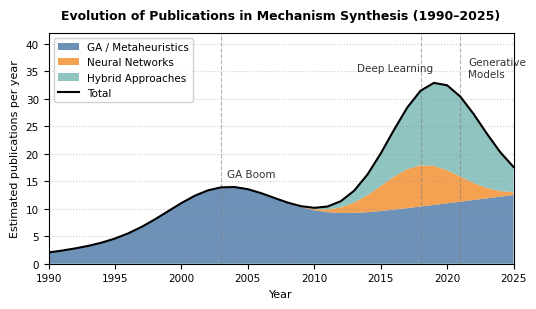

In [4]:
import matplotlib.pyplot as plt
import os
import glob
from numpy import arange, exp

# 1. Automated Filename System
try:
    notebook_files = glob.glob("*.ipynb")
    if notebook_files:
        notebook_name = notebook_files[0].replace('.ipynb', '')
    else:
        notebook_name = "ex12_3_publications_timeline"
except Exception:
    notebook_name = "ex12_3_publications_timeline"

# 2. Springer Publication Style Settings
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'

# Ensure required variables are defined locally if the previous cell wasn't run
try:
    _ = anios, base, pico_ga, pico_nn, pico_hyb
except NameError:
    anios = arange(1990, 2026)
    base = 2 + 0.3 * (anios - 1990)
    pico_ga = 8 * exp(-0.5 * ((anios - 2003) / 4) ** 2)
    pico_nn = 15 * exp(-0.5 * ((anios - 2018) / 3) ** 2)
    pico_hyb = 10 * exp(-0.5 * ((anios - 2021) / 3) ** 2)

# Data calculations (realigned components based on base and peak values)
ga_only  = base + pico_ga
nn_only  = 0.5 * pico_nn
hybrid   = 0.5 * pico_nn + pico_hyb
total_v  = ga_only + nn_only + hybrid

# 3. Figure Initialization (Controlled physical size: ~5.5 x 3.2 inches)
fig, ax = plt.subplots(figsize=(5.5, 3.2))

# Stackplot for evolution
ax.stackplot(anios, ga_only, nn_only, hybrid,
             labels=['GA / Metaheuristics', 'Neural Networks', 'Hybrid Approaches'],
             colors=['#4e79a7', '#f28e2b', '#76b7b2'], alpha=0.82)

# Overall total curve
ax.plot(anios, total_v, 'k-', linewidth=1.5, label='Total', zorder=5)

# 4. Strictly position milestones with custom offsets to avoid overlaps
# (x_offset, y_offset) designed to push text away from the line trajectory and labels
milestones = {
    2003: ('GA Boom', 0.4, 1.5),
    2018: ('Deep Learning', -4.8, 3.2),    # Pushed left and higher to clear the 2018 line and peak
    2021: ('Generative\nModels', 0.6, 3.2)  # Pushed right and higher to clear the 2021 line and the descending slope
}

for yr, (txt, x_off, y_off) in milestones.items():
    ax.axvline(yr, color='#7f7f7f', ls='--', alpha=0.6, lw=0.8)
    y_pos = total_v[yr-1990] + y_off
    ax.text(yr + x_off, y_pos, txt, fontsize=7.5, color='#333333',
            verticalalignment='bottom', horizontalalignment='left', zorder=10)

# 5. Labels and limits optimized for Springer layout
ax.set_xlabel('Year', fontsize=8)
ax.set_ylabel('Estimated publications per year', fontsize=8)
ax.set_title('Evolution of Publications in Mechanism Synthesis (1990–2025)',
             fontsize=9, fontweight='bold', pad=10)

ax.legend(loc='upper left', fontsize=7.5, frameon=True, framealpha=0.9)
ax.set_xlim(1990, 2025)
ax.set_ylim(0, 42) # Safe margin for the annotations
ax.grid(True, axis='y', linestyle=':', alpha=0.5, color='#999999')

ax.tick_params(axis='both', which='major', labelsize=7.5)

plt.tight_layout()

# 6. Double Export System
plt.savefig(f'{notebook_name}.pdf', format='pdf', bbox_inches='tight')
plt.savefig(f'{notebook_name}.png', format='png', dpi=600, bbox_inches='tight')
plt.show()

### 3. Projection for the 2026–2030 Period

In [ ]:
# Simple projection based on recent trend
anios_fut = arange(2025, 2031)

# Continuity model: hybrid post-peak moderate growth
base_fut = publicaciones[-1] + 1.5 * (anios_fut - 2025)
decay_hyb = 5 * exp(-0.5 * ((anios_fut - 2023) / 3) ** 2)
proyeccion = around(base_fut + decay_hyb).astype(int)

print("Estimated Projection of Publications 2026–2030")
print(f"{'Year':>6}  {'Est. Pubs':>15}  {'Cumulative':>10}")

acum = total
for yr, pub in zip(anios_fut, proyeccion):
    acum += pub
    print(f"{yr:>6}  {pub:>15}  {acum:>10}")

print("\nNote: Simplified projection; subject to technological shifts.")

Estimated Projection of Publications 2026–2030
  Year        Est. Pubs  Cumulative
  2025               23         580
  2026               24         604
  2027               24         628
  2028               25         653
  2029               26         679
  2030               27         706

Note: Simplified projection; subject to technological shifts.
